# 03 – Land cover (imperviousness and vegetation)

**Goal:** turn three rasters into a few numbers per 100 m cell that describe the **ground surface**: how much is sealed (asphalt, roofs, concrete), how green it is, and how much is covered by trees.

- **Input:** three rasters in `data/raw/` + `data/processed/cells.gpkg` (from `01_grid`)
- **Output:** `data/processed/ind_land_cover.csv` (one row per cell, joined to the grid by `cell_id`)

| raster | source | pixel | values |
|---|---|---|---|
| `imperviousness/CLMS_NVLCC_IMD_S2024_R10m_...tif` | Copernicus HRL Imperviousness Density 2024 | 10 m | 0–100 = % sealed, 255 = outside area |
| `NDVI/Ljubljana_NDVI_Export_2026.tif` | Sentinel-2 NDVI composite (GEE export) | ~10 m | −1 … 1 |
| `Canopy_height/Ljubljana_Canopy_Height_1m-...tif` | Meta/WRI global canopy height | ~1 m | tree height in m (0 = no canopy) |

**Indicators per cell:**

| column | meaning | why it matters |
|---|---|---|
| `imp_share` | mean imperviousness (share of the cell that is sealed, 0–1) | built-up ground incl. roads and parking, not only buildings |
| `ndvi_mean` | mean NDVI | how green the surface is (grass, crops and trees together) |
| `ndvi_neg_share` | share of pixels with NDVI < 0 (0–1) | rough hint of water, but also some dark roofs and asphalt; the real water mask comes later from NDWI |
| `can_cover` | share of the cell with canopy ≥ 3 m (0–1) | tree cover (shade) |
| `can_height` | mean height of the tree pixels (m), NaN if no trees | young/low vs mature/tall trees |

⚠️ The plan says **NDVI or canopy height, not both** as clustering inputs (open decision with Špela). We compute both here so that the choice can be made with numbers (section 10).

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterstats import zonal_stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

IMP_TIF = RAW / "imperviousness" / "CLMS_NVLCC_IMD_S2024_R10m_E46N25_03035_V01_R01.tif"
NDVI_TIF = RAW / "NDVI" / "Ljubljana_NDVI_Export_2026.tif"
CANOPY_TIF = RAW / "Canopy_height" / "Ljubljana_Canopy_Height_1m-0000000000-0000000000.tif"

IMP_OUTSIDE = 255      # "outside area" code in the imperviousness raster
TREE_MIN_HEIGHT = 3    # m, canopy pixels at least this tall count as trees (0–2 m is mostly grass, shrubs and model noise)

## 2. Load the grid and look at the rasters
The rasters come in **different coordinate systems** from our grid (EPSG:3794):
- imperviousness: ETRS89 / LAEA Europe (EPSG:3035), the standard for Copernicus products
- NDVI and canopy height: WGS84 longitude/latitude (EPSG:4326), the default of Google Earth Engine exports

For each raster we check that it covers the whole grid.

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
assert cells.crs.to_epsg() == 3794

for name, path in [("imperviousness", IMP_TIF), ("NDVI", NDVI_TIF), ("canopy", CANOPY_TIF)]:
    with rasterio.open(path) as r:
        gb = cells.to_crs(r.crs).total_bounds
        covers = r.bounds.left <= gb[0] and r.bounds.bottom <= gb[1] and r.bounds.right >= gb[2] and r.bounds.top >= gb[3]
        print(f"{name:15s} {r.crs}  {r.width:>6,} x {r.height:>6,} px  dtype {r.dtypes[0]:8s} nodata {r.nodata}  covers grid: {covers}")
        assert covers

imperviousness  EPSG:3035  10,000 x 10,000 px  dtype uint8    nodata None  covers grid: True
NDVI            EPSG:4326   7,171 x  5,009 px  dtype float32  nodata None  covers grid: True


canopy          EPSG:4326  65,536 x 50,079 px  dtype uint8    nodata None  covers grid: True


**What we take from this:**
- All three rasters cover the whole municipality.
- None of them has a `nodata` value set in the file, so we must tell the code which values mean "no data": 255 for imperviousness and NaN for NDVI. Canopy height uses 0 for "no canopy", which is a real value, not missing data.
- The canopy file name ends in `-0000000000-0000000000`. Earth Engine splits large exports into tiles and this is the first one. It already covers all of MOL, so we don't need the other tiles.

## 3. How we compute a value per cell (zonal statistics)
For every cell we take all raster pixels whose **centre** lies inside the cell and summarise them (mean, share above a threshold).

Instead of reprojecting the rasters to EPSG:3794, we **reproject the cells into each raster's coordinate system**. That way the pixel values stay exactly as published. Warping a raster would resample it, which slightly changes the values. A 100 m square stays (almost) a square after reprojection, so nothing is lost.

Expected pixels per cell: ~100 for imperviousness (10 × 10 m), ~140 for NDVI (its pixels are ~10 × 7 m in lon/lat) and ~14,000 for canopy height (~1 × 0.7 m).

In [3]:
def per_cell(path, nodata=None, stats=("mean", "count"), add_stats=None):
    # Zonal statistics for every grid cell, with the cells reprojected to the raster's CRS
    with rasterio.open(path) as r:
        crs = r.crs
    zs = zonal_stats(cells.to_crs(crs), path, stats=list(stats), nodata=nodata, add_stats=add_stats)
    return pd.DataFrame(zs, index=cells["cell_id"])

## 4. Imperviousness
The value of a pixel is the **percentage of its 100 m² that is sealed**. The mean over a cell is therefore the sealed share of the cell. We divide by 100 to get a share (0–1), the same scale as `bld_coverage`.

In [4]:
imp = per_cell(IMP_TIF, nodata=IMP_OUTSIDE)
print(f"Pixels per cell: {imp['count'].min()}–{imp['count'].max()} (median {imp['count'].median():.0f})")
imp_share = imp["mean"] / 100
imp_share.describe().round(3)

Pixels per cell: 99–101 (median 100)


count    27505.000
mean         0.134
std          0.242
min          0.000
25%          0.000
50%          0.000
75%          0.152
max          1.000
Name: mean, dtype: float64

## 5. NDVI
NDVI = (NIR − Red) / (NIR + Red), which measures how much living green vegetation there is. Rough guide: < 0 water, 0–0.2 bare soil, rock or roofs, 0.2–0.5 sparse vegetation, > 0.6 dense vegetation.

We also count the share of negative pixels, which is a cheap hint of water (rivers, ponds). It is not clean: some dark roofs and asphalt also have NDVI slightly below 0 (see the most sealed cells in section 8). The proper water mask comes later from NDWI.

In [5]:
ndvi = per_cell(NDVI_TIF, nodata=np.nan, add_stats={"neg_share": lambda a: float((a < 0).mean())})
print(f"Pixels per cell: {ndvi['count'].min()}–{ndvi['count'].max()} (median {ndvi['count'].median():.0f})")
print(f"Cells without NDVI: {ndvi['mean'].isna().sum()}")
ndvi[["mean", "neg_share"]].describe().round(3)

Pixels per cell: 140–157 (median 140)
Cells without NDVI: 0


,mean,neg_share
count,27505.000,27505.000
mean,0.681,0.005
std,0.218,0.035
min,-0.216,0.000
25%,0.529,0.000
50%,0.758,0.000
75%,0.869,0.000
max,0.931,0.868


## 6. Canopy height
Two numbers per cell:
- **cover** = share of the cell with canopy ≥ 3 m (how much shade there is)
- **height** = mean height of only those tree pixels (how tall the trees are)

We keep them apart because they mean different things. A cell half covered by 20 m trees and a cell fully covered by 10 m trees have the same mean over the whole cell (10 m), but they are very different places.
`can_height` is NaN in cells without trees: the height of trees that aren't there is undefined, not 0.

This is the heaviest step: about 400 million pixels, a few minutes.

In [6]:
def tree_height(a):
    trees = a[a >= TREE_MIN_HEIGHT]
    return float(trees.mean()) if trees.count() > 0 else np.nan

canopy = per_cell(
    CANOPY_TIF,
    nodata=-999,  # the raster has no missing values; set explicitly so rasterstats doesn't warn
    stats=("count",),
    add_stats={"cover": lambda a: float((a >= TREE_MIN_HEIGHT).mean()), "height": tree_height},
)
print(f"Pixels per cell: {canopy['count'].min():,}–{canopy['count'].max():,} (median {canopy['count'].median():,.0f})")
canopy[["cover", "height"]].describe().round(3)

Pixels per cell: 14,340–14,474 (median 14,410)


,cover,height
count,27505.000,25261.000
mean,0.449,10.317
std,0.402,4.775
min,0.000,3.000
25%,0.055,6.319
50%,0.307,9.275
75%,0.924,14.091
max,1.000,24.349


## 7. Combine

In [7]:
result = pd.DataFrame({
    "imp_share": imp_share,
    "ndvi_mean": ndvi["mean"],
    "ndvi_neg_share": ndvi["neg_share"],
    "can_cover": canopy["cover"],
    "can_height": canopy["height"],
})
cols = list(result.columns)
print(result.isna().sum())
result.describe().round(3).T

imp_share            0
ndvi_mean            0
ndvi_neg_share       0
can_cover            0
can_height        2244
dtype: int64


,count,mean,std,min,25%,50%,75%,max
imp_share,27505.0,0.134,0.242,0.000,0.000,0.000,0.152,1.000
ndvi_mean,27505.0,0.681,0.218,-0.216,0.529,0.758,0.869,0.931
ndvi_neg_share,27505.0,0.005,0.035,0.000,0.000,0.000,0.000,0.868
can_cover,27505.0,0.449,0.402,0.000,0.055,0.307,0.924,1.000
can_height,25261.0,10.317,4.775,3.000,6.319,9.275,14.091,24.349


## 8. Sanity checks
1. **Imperviousness vs building coverage** (from `02_buildings`): roofs are sealed, so imperviousness should be **at least** building coverage in almost every cell. Usually it is clearly higher, because roads and parking also count. Small exceptions are fine, because the two datasets come from different years and sources.
2. **Imperviousness vs NDVI:** sealed surfaces are not green, so we expect a strong negative relation.
3. The most sealed cells and the most tree-covered cells should be places we recognise.

Cells where imperviousness is >10 pp below building coverage: 28 of 16,369
Median (imperviousness - building coverage) in built cells: 0.23


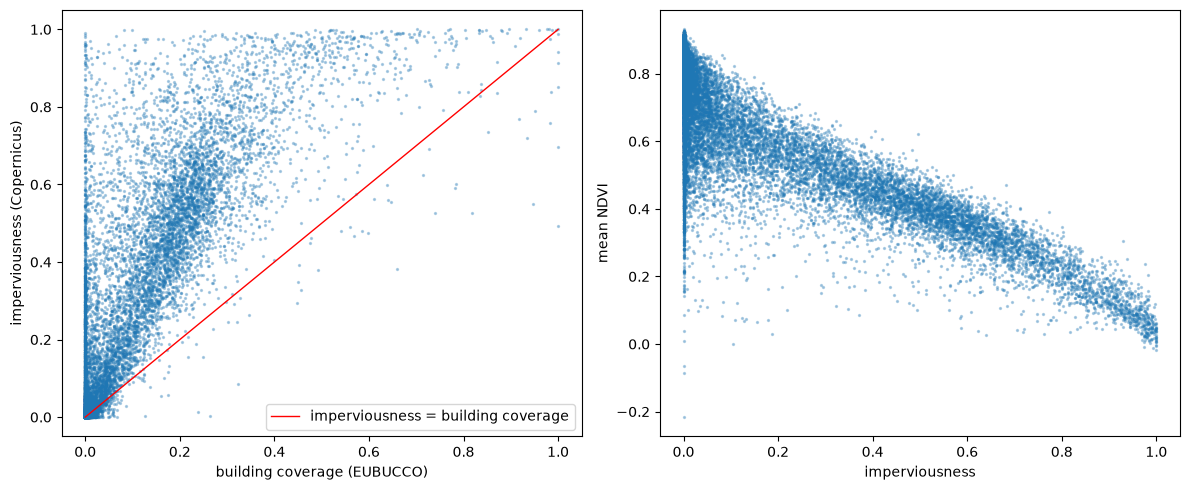

In [8]:
bld = pd.read_csv(PROCESSED / "ind_buildings.csv", index_col="cell_id")
both = result.join(bld[["bld_in_data", "bld_coverage"]])
both = both[both["bld_in_data"]]

below = both["imp_share"] < both["bld_coverage"] - 0.1
print(f"Cells where imperviousness is >10 pp below building coverage: {below.sum()} of {len(both):,}")
print(f"Median (imperviousness - building coverage) in built cells: "
      f"{(both['imp_share'] - both['bld_coverage'])[both['bld_coverage'] > 0].median():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(both["bld_coverage"], both["imp_share"], s=2, alpha=0.3)
axes[0].plot([0, 1], [0, 1], color="red", linewidth=1, label="imperviousness = building coverage")
axes[0].set_xlabel("building coverage (EUBUCCO)")
axes[0].set_ylabel("imperviousness (Copernicus)")
axes[0].legend()
axes[1].scatter(result["imp_share"], result["ndvi_mean"], s=2, alpha=0.3)
axes[1].set_xlabel("imperviousness")
axes[1].set_ylabel("mean NDVI")
plt.tight_layout()
plt.show()

In [9]:
xy = cells.set_index("cell_id")[["E", "N"]]
print("Most sealed cells:")
print(result.nlargest(5, "imp_share")[cols].join(xy).round(2).to_string())
print("\nMost tree-covered cells:")
print(result.nlargest(5, "can_cover")[cols].join(xy).round(2).to_string())
print("\nTallest trees (cells with at least 25% tree cover):")
print(result[result["can_cover"] >= 0.25].nlargest(5, "can_height")[cols].join(xy).round(2).to_string())

Most sealed cells:
                   imp_share  ndvi_mean  ndvi_neg_share  can_cover  can_height       E       N
cell_id                                                                                       
SIHM100_4640_975         1.0      -0.02            0.64        0.0         NaN  464000   97500
SIHM100_4656_1027        1.0       0.01            0.21        0.0         NaN  465600  102700
SIHM100_4648_1032        1.0       0.05            0.10        0.0         NaN  464800  103200
SIHM100_4608_1044        1.0       0.03            0.07        0.0         NaN  460800  104400
SIHM100_4612_1044        1.0       0.02            0.20        0.0         3.0  461200  104400

Most tree-covered cells:
                  imp_share  ndvi_mean  ndvi_neg_share  can_cover  can_height       E      N
cell_id                                                                                     
SIHM100_4733_943        0.0       0.90             0.0        1.0       13.83  473300  94300
SIHM100_471

## 9. Maps
The black outline is the settlement boundary used for the building data, for orientation.

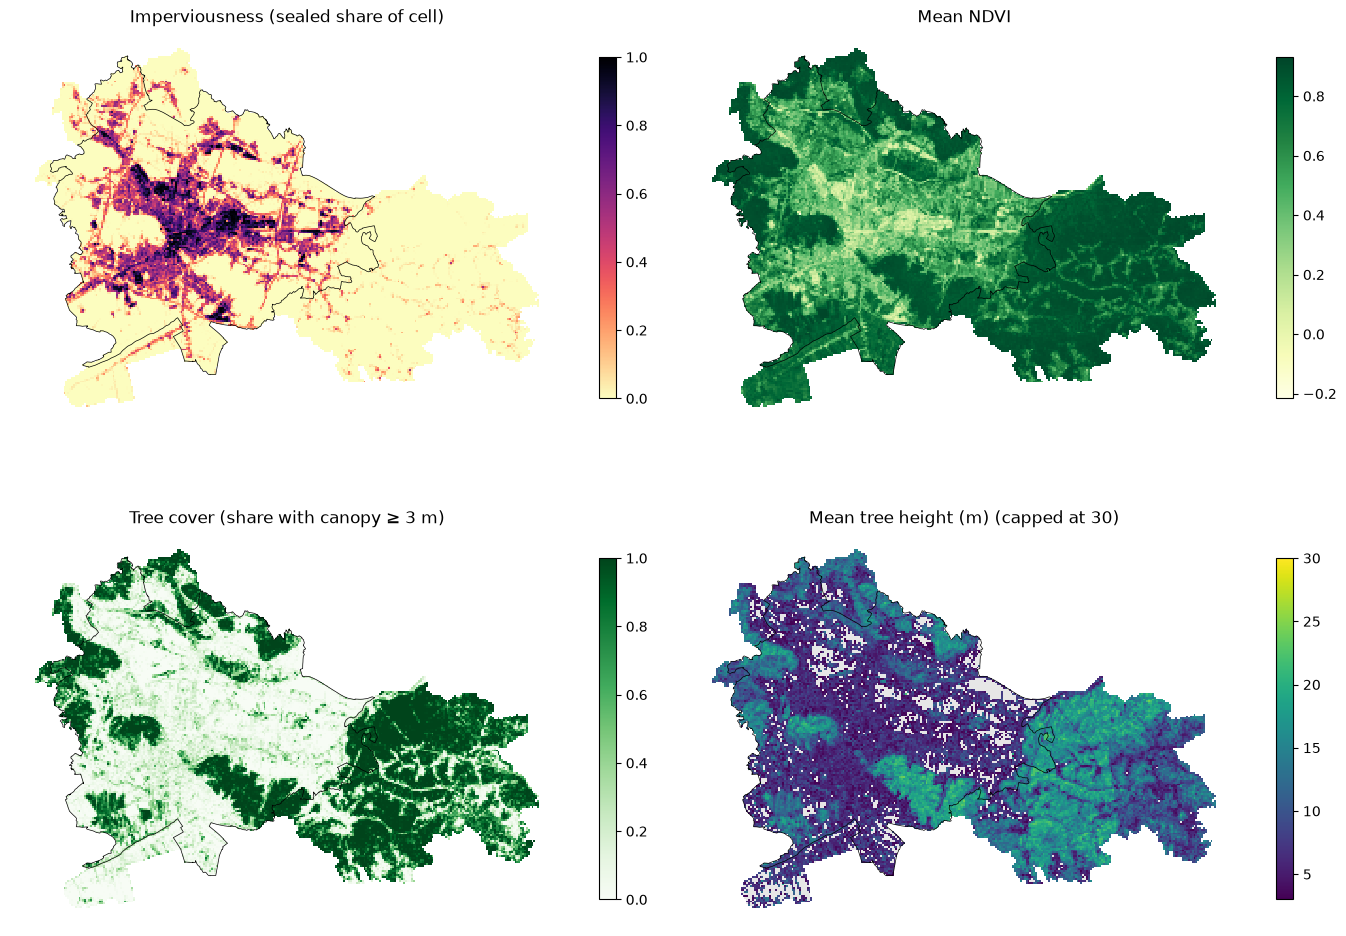

In [10]:
extent = gpd.read_file(RAW / "LJ_EUBBUCO" / "ljubljana_eubucco_v02.gpkg", layer="boundary")
gdf = cells[["cell_id", "geometry"]].merge(result.reset_index(), on="cell_id")

maps = [
    ("imp_share", "Imperviousness (sealed share of cell)", "magma_r", None),
    ("ndvi_mean", "Mean NDVI", "YlGn", None),
    ("can_cover", f"Tree cover (share with canopy ≥ {TREE_MIN_HEIGHT} m)", "Greens", None),
    ("can_height", "Mean tree height (m)", "viridis", 30),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (col, title, cmap, vmax) in zip(axes.flat, maps):
    gdf.plot(ax=ax, color="#e6e6e6", linewidth=0)
    gdf.dropna(subset=[col]).plot(ax=ax, column=col, cmap=cmap, vmax=vmax, linewidth=0,
                                  legend=True, legend_kwds={"shrink": 0.6})
    extent.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(title + (f" (capped at {vmax})" if vmax else ""))
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "03_land_cover.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. How do the indicators relate? (NDVI or canopy height?)
Same idea as in `02_buildings`: if two indicators are almost the same, clustering would count that information twice.

For the **NDVI vs canopy** decision, the useful question is what each one sees that the other doesn't:
- NDVI is high for **all** green surfaces: lawns, fields, parks and forest.
- Canopy cover is high only for **trees**. A football pitch has high NDVI and no canopy.

If NDVI and canopy cover are only moderately correlated, they carry different information, and the choice matters for the types we get.

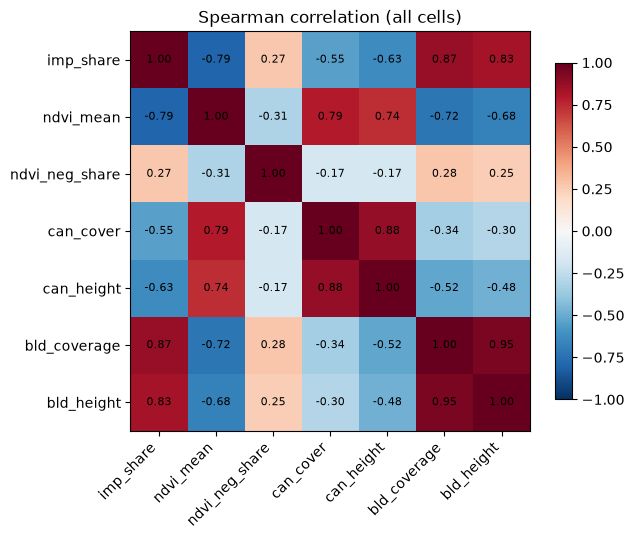

In [11]:
corr = result[cols].join(bld[["bld_coverage", "bld_height"]]).corr(method="spearman")
labels = list(corr.columns)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (all cells)")
plt.tight_layout()
plt.show()

Cells with NDVI > 0.6 but tree cover < 10%: 3,136 of 27,505


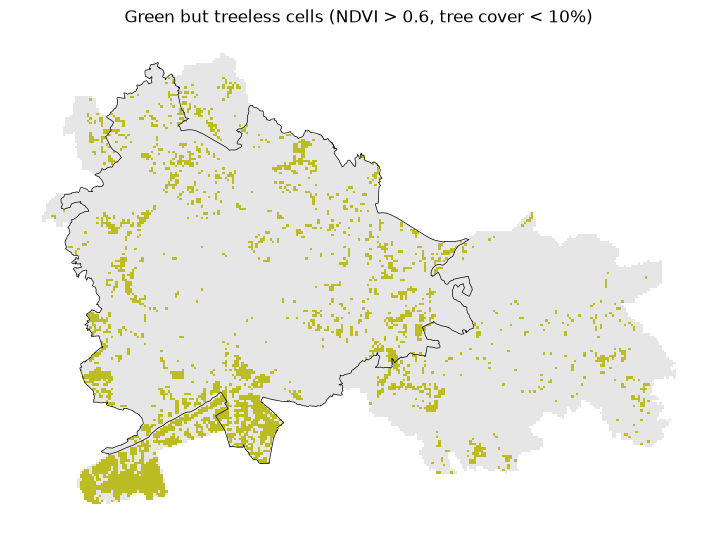

In [12]:
# Green but treeless: high NDVI, low canopy (lawns, fields, sports grounds)
green_no_trees = (result["ndvi_mean"] > 0.6) & (result["can_cover"] < 0.1)
print(f"Cells with NDVI > 0.6 but tree cover < 10%: {green_no_trees.sum():,} of {len(result):,}")

ax = gdf.plot(color="#e6e6e6", linewidth=0, figsize=(9, 7))
gdf[green_no_trees.values].plot(ax=ax, color="tab:olive", linewidth=0)
extent.boundary.plot(ax=ax, color="black", linewidth=0.5)
ax.set_title("Green but treeless cells (NDVI > 0.6, tree cover < 10%)")
ax.set_axis_off()
plt.show()

## 11. Save

In [13]:
out = result.reset_index()
out.to_csv(PROCESSED / "ind_land_cover.csv", index=False)
print(f"Saved {len(out):,} rows to {PROCESSED / 'ind_land_cover.csv'}")
out.head()

Saved 27,505 rows to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\ind_land_cover.csv


,cell_id,imp_share,ndvi_mean,ndvi_neg_share,can_cover,can_height
0,SIHM100_4564_929,0.0000,0.793007,0.0,0.094781,7.800587
1,SIHM100_4565_929,0.0000,0.691624,0.0,0.008002,4.843478
2,SIHM100_4566_929,0.0000,0.672743,0.0,0.044381,9.749609
3,SIHM100_4567_929,0.0000,0.751415,0.0,0.064731,10.007511
4,SIHM100_4570_929,0.1387,0.559014,0.0,0.022018,5.820189


## Summary
- Five land-cover indicators per cell for all 27,505 cells (all three rasters cover the whole of MOL), saved to `data/processed/ind_land_cover.csv`.
- Cells were reprojected into each raster's coordinate system, so the raster values were not resampled.
- Sanity checks pass: imperviousness is below building coverage (by >10 pp) in only 28 of 16,369 cells. In built cells it is typically 0.23 higher, which is roads and parking. NDVI falls steadily as imperviousness rises.

**NDVI or canopy height? What the numbers say (Spearman, all cells):**
- `ndvi_mean` vs `imp_share`: **−0.79**. NDVI is to a large extent "the opposite of sealed", so it partly repeats imperviousness.
- `can_cover` vs `imp_share`: **−0.55**. Tree cover carries more information that imperviousness doesn't have.
- `ndvi_mean` vs `can_cover`: 0.79. About 3,100 cells are green but treeless (NDVI > 0.6, tree cover < 10%), mainly meadows and fields on Ljubljansko barje, plus lawns and sports grounds.
- → Arguing for **canopy cover**: it adds more beyond imperviousness and separates "green with shade" from "green without shade". NDVI is the more standard, simpler choice. To be decided with Špela.
- `can_cover` and `can_height` are strongly related (0.88), so if canopy is chosen, start with `can_cover` only.

**Limitations / to check:**
- **NDVI date:** the file name says "Export_2026", but not which period or season the composite covers. NDVI changes a lot over the year (fields are bare in winter), so this must be documented. A summer (June–August) median is the usual choice.
- Canopy height is a global model (Meta/WRI, trained on lidar), so it is less exact than local lidar (CLSS). The 3 m tree threshold is our choice.
- Imperviousness is 2024, buildings come from EUBUCCO and population from 2025. Small time mismatches are acceptable for a structural characterisation.

**Next:** decide NDVI vs canopy height with Špela (section 10 gives the numbers), then Urban Atlas and PT accessibility for the remaining pilot indicators.